# Challenge Advisor meeting 4: answers to the meeting-three notes (issue #22)

**Author:** Kamsi Ozorji · **Date:** 2026-10-27 · **Sub-issues:** #24 confounder, #25 crosswalk + Kendall,
#26 exposure vs risk + case studies, #27 decision log ([`weekly-notes/decision-log.md`](../weekly-notes/decision-log.md))

**Goal:** answer every TODO in [`challenger-advisor-meeting-three.txt`](../weekly-notes/challenger-advisor-meeting-three.txt),
one section and one figure each.

**Reads:** `ai_risk_v1.csv` and `ai_risk_v1_all_occupations.csv` (Milestone 1 v1), the two crosswalk coverage logs in
`data/interim/`, and the raw BLS SOC 2010→2018 crosswalk. **Writes:** figures `notebooks/figures/ca4_*.png` and
`data/interim/hand_crosswalk_dropped_codes.csv`.

## TL;DR

| Note from meeting three | Section | Short answer |
|---|---|---|
| "There's a confounding variable, look for it" (Simpson's paradox, in O\*NET) | §1 | **O\*NET Job Zone (education/preparation level).** Overall, Eloundou and Frey-Osborne disagree (ρ = −0.26), but within every Job Zone the correlation is positive (ρ = +0.15 to +0.39; 6 of 8 bootstrap intervals exclude zero, and controlling for Job Zone gives +0.19). AIOE vs Frey-Osborne flips the same way. |
| "Try the kindle and see, if it changes the coorelations" (read as Kendall's τ) | §2 | Kendall's τ is smaller in size (as usual) but every sign and every conclusion is the same as Spearman. |
| "Build a new crosswalk with a human transformation" / "transformed vs untransformed" / "Frey-Osborne may end up a bit different" | §3 | Hand-mapping the 18 codes the automated crosswalk drops adds 75 occupations (physicians, nurses, postsecondary teachers). Correlations move by at most 0.06 (Frey-Osborne pairs most); dropping all split/merged codes moves them by at most 0.05. The crosswalk is not driving the results. |
| "Trade datasets and see what that does for your analyses" | §4 | Swapping in Eloundou's human-rated or γ scores keeps the same pattern. The narrower α variant is uncorrelated with Frey-Osborne overall, but *every* variant is positive within every Job Zone. |
| "Exposure vs risk" | §5 | Eloundou and AIOE measure *exposure* (AI can do parts of the job, which can help the worker); Frey-Osborne measures *risk* (the whole job is automated). That is why they disagree on high-education jobs. Within every Job Zone, only risk tracks BLS-projected decline. |
| "Case studies relevant to most people: school teachers, office workers" | §6 | Teachers: exposed (especially on AIOE) but near-zero automation risk. General office clerks and secretaries: high on all three. Customer service reps and retail sales: the indices split. |
| "Lots of graphs" | all | One figure per section, saved to `notebooks/figures/ca4_*.png`. |
| "Document the decisions, using a decision log" | — | [`weekly-notes/decision-log.md`](../weekly-notes/decision-log.md), TL;DR first. |
| "Data mining, more feature engineering" / "O\*NET should help a lot" | §1 | The O\*NET features in v1 are what found the confounder; the abilities/skills summaries track it even more closely than Job Zone. |

The numbers in this table are the ones the cells below print; rerun to check.

## Setup

Runs on **Google Colab** (mounts Drive) or **locally** (uses the repo folder). Any input missing from Drive is downloaded
from the public GitHub repo, as in the other notebooks.

In [1]:
import os
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', None)

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/BTT Fall AI Studio (swytch 1b)'
except ImportError:
    BASE = os.path.dirname(os.getcwd())  # repo folder (this notebook is in notebooks/)

GITHUB_RAW = 'https://raw.githubusercontent.com/Break-Through-Tech/Swytch-1B-do-ai-job-risk-indices-agree/main'
INPUTS = [
    'data/processed/milestone_1/v1/ai_risk_v1.csv',
    'data/processed/milestone_1/v1/ai_risk_v1_all_occupations.csv',
    'data/interim/frey_osborne_coverage_log.csv',
    'data/interim/aioe_coverage_log.csv',
    'data/raw/soc_2010_to_2018_crosswalk.xlsx',
]
for rel in INPUTS:
    path = f'{BASE}/{rel}'
    if not os.path.exists(path):
        print('downloading', rel)
        os.makedirs(os.path.dirname(path), exist_ok=True)
        urllib.request.urlretrieve(f'{GITHUB_RAW}/{rel}', path)

FIGURES = f'{BASE}/notebooks/figures'
os.makedirs(FIGURES, exist_ok=True)

v1 = pd.read_csv(f'{BASE}/data/processed/milestone_1/v1/ai_risk_v1.csv', dtype={'soc': str, 'major_group': str})
RANKS = ['pct_eloundou_beta', 'pct_aioe', 'pct_frey_osborne']
SHORT = {'pct_eloundou_beta': 'Eloundou', 'pct_aioe': 'AIOE', 'pct_frey_osborne': 'Frey-Osborne'}
PAIRS = [('pct_eloundou_beta', 'pct_aioe'), ('pct_eloundou_beta', 'pct_frey_osborne'), ('pct_aioe', 'pct_frey_osborne')]

# Job Zone is an average over O*NET children, so a few are fractional: bin to the nearest zone, halves round down
v1['job_zone'] = pd.cut(v1['onet_job_zone'], bins=[0, 2.5, 3.5, 4.5, 5], labels=[2, 3, 4, 5]).astype(int)


def pair_table(df, pairs=PAIRS, method='spearman'):
    # One row per index pair: correlation and its p-value
    corr = stats.spearmanr if method == 'spearman' else stats.kendalltau
    rows = []
    for a, b in pairs:
        r, p = corr(df[a], df[b])
        rows.append({'pair': f'{SHORT.get(a, a)} vs {SHORT.get(b, b)}', 'rho': round(r, 2), 'p': p})
    return pd.DataFrame(rows).set_index('pair')


print(len(v1), 'occupations;', v1['job_zone'].value_counts().sort_index().to_dict())

693 occupations; {2: 307, 3: 171, 4: 148, 5: 67}


## 1. The confounding variable (Simpson's paradox) — sub-issue #24

**Simpson's paradox:** a trend that shows up in the combined data reverses or disappears inside each group, because
a third variable drives both. The advisor said the variable is in O\*NET.

**Check:** correlate the indices across all 693 occupations, then again inside each O\*NET Job Zone (1 = little
preparation, 5 = extensive, e.g. a graduate degree). Zone 1 has no occupations in the table.

In [2]:
rows = []
for zone, group in [('all', v1)] + list(v1.groupby('job_zone')):
    table = pair_table(group)
    for pair, row in table.iterrows():
        rows.append({'job_zone': zone, 'n': len(group), 'pair': pair, 'rho': row['rho'], 'p': row['p']})
by_zone = pd.DataFrame(rows)
by_zone.pivot(index='job_zone', columns='pair', values='rho').join(
    by_zone.groupby('job_zone')['n'].first()).loc[['all', 2, 3, 4, 5]]

,AIOE vs Frey-Osborne,Eloundou vs AIOE,Eloundou vs Frey-Osborne,n
job_zone,,,,
all,-0.36,0.86,-0.26,693
2,0.16,0.75,0.15,307
3,0.20,0.81,0.16,171
4,0.16,0.43,0.24,148
5,0.24,0.48,0.39,67


Eloundou vs Frey-Osborne and AIOE vs Frey-Osborne are **negative overall but positive in every Job Zone**. That is
Simpson's paradox. Eloundou vs AIOE stays positive throughout (both measure the same thing; see §5).

**Is the reversal real or noise?** Bootstrap 95% intervals for the within-zone correlations (1,000 resamples):

In [3]:
rng = np.random.default_rng(0)


def boot_ci(df, a, b, n_boot=1000):
    values = []
    for _ in range(n_boot):
        sample = df.iloc[rng.integers(0, len(df), len(df))]
        values.append(stats.spearmanr(sample[a], sample[b])[0])
    return np.percentile(values, [2.5, 97.5]).round(2)


rows = []
for zone, group in v1.groupby('job_zone'):
    for a, b in PAIRS[1:]:
        low, high = boot_ci(group, a, b)
        rows.append({'job_zone': zone, 'pair': f'{SHORT[a]} vs {SHORT[b]}', 'n': len(group),
                     'rho': round(stats.spearmanr(group[a], group[b])[0], 2), 'ci_low': low, 'ci_high': high})
pd.DataFrame(rows)

,job_zone,pair,n,rho,ci_low,ci_high
0,2,Eloundou vs Frey-Osborne,307,0.15,0.02,0.27
1,2,AIOE vs Frey-Osborne,307,0.16,0.04,0.28
2,3,Eloundou vs Frey-Osborne,171,0.16,-0.01,0.32
3,3,AIOE vs Frey-Osborne,171,0.20,0.05,0.33
4,4,Eloundou vs Frey-Osborne,148,0.24,0.07,0.40
5,4,AIOE vs Frey-Osborne,148,0.16,-0.00,0.31
6,5,Eloundou vs Frey-Osborne,67,0.39,0.19,0.58
7,5,AIOE vs Frey-Osborne,67,0.24,0.01,0.45


The point estimate is positive in every zone for both pairs, and 6 of the 8 intervals exclude zero (the two that
touch it are Zone 3 Eloundou and Zone 4 AIOE). The pooled test below, which controls for Job Zone across all 693
occupations, is the stronger evidence.

**Is Job Zone the only confounder?** Below, every O\*NET feature is correlated with the *gap* between the indices
(Eloundou rank minus Frey-Osborne rank). Then a *partial* correlation removes each candidate: rank both indices and the
candidate, take what the candidate cannot explain (regression residuals), and correlate those.

In [4]:
ONET = [c for c in v1.columns if c.startswith('onet_') and c != 'onet_status']
gap = v1['pct_eloundou_beta'] - v1['pct_frey_osborne']
gap_corr = v1[ONET + ['bls_median_wage']].corrwith(gap, method='spearman').sort_values(key=abs, ascending=False)


def partial_spearman(df, a, b, control):
    ranks = df[[a, b, control]].dropna().rank()  # a few occupations lack some O*NET features
    X = np.column_stack([np.ones(len(ranks)), ranks[control]])
    resid = lambda col: ranks[col] - X @ np.linalg.lstsq(X, ranks[col], rcond=None)[0]
    return stats.pearsonr(resid(a), resid(b))[0]


top = gap_corr.head(6).index.tolist()
pd.DataFrame({
    'corr_with_gap': gap_corr[top].round(2),
    'Eloundou vs F-O, controlling': [round(partial_spearman(v1, 'pct_eloundou_beta', 'pct_frey_osborne', c), 2) for c in top],
    'AIOE vs F-O, controlling': [round(partial_spearman(v1, 'pct_aioe', 'pct_frey_osborne', c), 2) for c in top],
}).rename_axis('control')

,corr_with_gap,"Eloundou vs F-O, controlling","AIOE vs F-O, controlling"
control,,,
onet_abl_verbal,0.84,0.33,0.34
onet_skl_foundational,0.82,0.27,0.24
onet_abl_reasoning,0.79,0.22,0.20
onet_job_zone,0.77,0.19,0.17
onet_skl_ways_of_working,0.76,0.15,0.16
onet_skl_systems,0.73,0.12,0.08


Controlling for Job Zone, or for any of the education-linked abilities and skills (verbal ability, reasoning,
foundational skills), turns the negative correlation positive. These features all measure roughly the same thing:
**how much education and cognitive preparation a job needs**. Job Zone is the simplest single label for it.

The same check on the 588 occupations with no split or merged SOC codes (so the crosswalk cannot be the cause):

In [5]:
clean = v1[~v1['any_provenance_flag']]
rows = []
for zone, group in [('all', clean)] + list(clean.groupby('job_zone')):
    rows.append({'job_zone': zone, 'n': len(group),
                 'Eloundou vs F-O': round(stats.spearmanr(group['pct_eloundou_beta'], group['pct_frey_osborne'])[0], 2),
                 'AIOE vs F-O': round(stats.spearmanr(group['pct_aioe'], group['pct_frey_osborne'])[0], 2)})
pd.DataFrame(rows).set_index('job_zone')

,n,Eloundou vs F-O,AIOE vs F-O
job_zone,,,
all,588,-0.22,-0.31
2,284,0.18,0.19
3,140,0.16,0.20
4,110,0.37,0.25
5,54,0.37,0.34


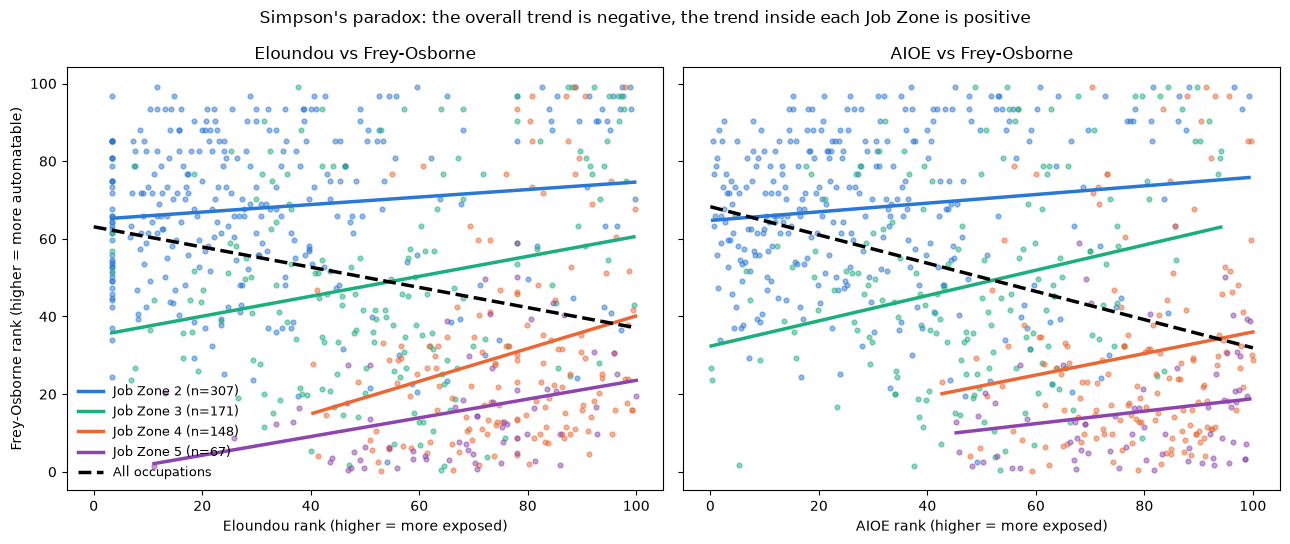

In [6]:
ZONE_COLORS = {2: '#2a78d6', 3: '#1baf7a', 4: '#eb6834', 5: '#8e44ad'}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, x in zip(axes, ['pct_eloundou_beta', 'pct_aioe']):
    for zone, group in v1.groupby('job_zone'):
        ax.scatter(group[x], group['pct_frey_osborne'], s=12, alpha=0.5, color=ZONE_COLORS[zone])
        slope, intercept = np.polyfit(group[x], group['pct_frey_osborne'], 1)
        xs = np.array([group[x].min(), group[x].max()])
        ax.plot(xs, intercept + slope * xs, color=ZONE_COLORS[zone], lw=2.5, label=f'Job Zone {zone} (n={len(group)})')
    slope, intercept = np.polyfit(v1[x], v1['pct_frey_osborne'], 1)
    ax.plot([0, 100], [intercept, intercept + slope * 100], color='black', lw=2.5, ls='--', label='All occupations')
    ax.set_xlabel(f'{SHORT[x]} rank (higher = more exposed)')
    ax.set_title(f'{SHORT[x]} vs Frey-Osborne')
axes[0].set_ylabel('Frey-Osborne rank (higher = more automatable)')
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Simpson's paradox: the overall trend is negative, the trend inside each Job Zone is positive")
fig.tight_layout()
fig.savefig(f'{FIGURES}/ca4_simpsons_paradox.png', dpi=130)
plt.show()

**Takeaway:** the indices look like they disagree mainly because Frey-Osborne rates low-education jobs as
automatable while Eloundou and AIOE rate high-education jobs as exposed. Compare jobs *at the same education level*
and the indices lean the same way (weakly, ρ ≈ 0.15–0.4) on which ones are more at risk. Any agreement analysis should report results within
Job Zone, not just overall.

## 2. Kendall's τ vs Spearman's ρ — sub-issue #25

Spearman correlates the ranks. Kendall counts how often two occupations are ordered the same way by both indices; it
is usually smaller in size (often about ⅔ of ρ) and less sensitive to a few extreme occupations.

In [7]:
kendall = pd.DataFrame({'spearman_rho': pair_table(v1)['rho'], 'kendall_tau': pair_table(v1, method='kendall')['rho']})
for zone, group in v1.groupby('job_zone'):
    kendall[f'tau_zone_{zone}'] = pair_table(group, method='kendall')['rho']
kendall

,spearman_rho,kendall_tau,tau_zone_2,tau_zone_3,tau_zone_4,tau_zone_5
pair,,,,,,
Eloundou vs AIOE,0.86,0.66,0.57,0.61,0.29,0.34
Eloundou vs Frey-Osborne,-0.26,-0.18,0.11,0.10,0.17,0.26
AIOE vs Frey-Osborne,-0.36,-0.25,0.11,0.12,0.10,0.16


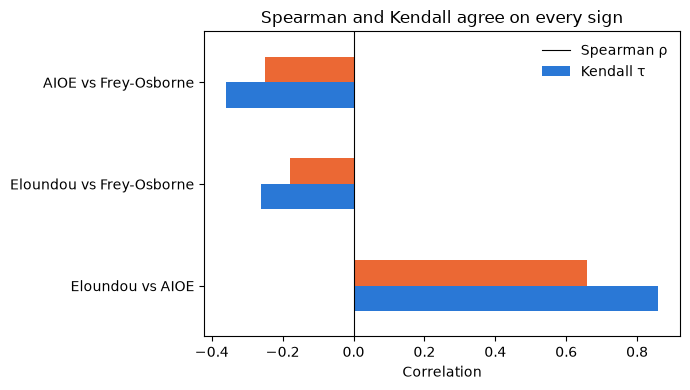

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
kendall[['spearman_rho', 'kendall_tau']].plot.barh(ax=ax, color=['#2a78d6', '#eb6834'])
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Correlation')
ax.set_ylabel('')
ax.set_title('Spearman and Kendall agree on every sign')
ax.legend(['Spearman ρ', 'Kendall τ'], frameon=False)
fig.tight_layout()
fig.savefig(f'{FIGURES}/ca4_kendall_vs_spearman.png', dpi=130)
plt.show()

**Takeaway:** Kendall does not change any conclusion, including the within-Job-Zone reversal. Spearman stays the
headline measure; Kendall is reported as a robustness check.

## 3. Crosswalk sensitivity: hand-mapped vs automated vs untransformed — sub-issue #25

Frey-Osborne and AIOE use SOC 2010 codes; everything else uses SOC 2018. Milestone 1 translated them with the BLS
crosswalk, which **dropped 17 Frey-Osborne codes and 1 AIOE code**: they are broad or older codes (e.g. `29-1060`
Physicians and Surgeons) that are not in the crosswalk's 2010 column.

**Human transformation (new):** map each dropped code by hand, using the crosswalk itself rather than memory:
1. match the title to a 2010 title in the crosswalk (ignoring spaces and punctuation), else
2. take every 2010 code that starts with the dropped code's broad prefix (e.g. `29-106*`), else
3. for the two codes neither rule finds, pick the 2010 codes by hand (listed in `MANUAL`).

A recovered score only fills an occupation that had **no** score from that index; it never overwrites one.

In [9]:
import re

cw = pd.read_excel(f'{BASE}/data/raw/soc_2010_to_2018_crosswalk.xlsx', sheet_name='Sorted by 2010', skiprows=8)
cw = cw.rename(columns={'2010 SOC Code': 'soc2010', '2010 SOC Title': 'title_2010', '2018 SOC Code': 'soc2018'})
cw = cw.dropna(subset=['soc2010'])
title_key = lambda s: re.sub(r'[^a-z]', '', str(s).lower())
cw['key'] = cw['title_2010'].map(title_key)

# Neither rule finds these two; 2010 codes chosen by reading the crosswalk
MANUAL = {
    '39-4831': ['39-4031', '11-9061'],             # Funeral service managers, directors, morticians, undertakers
    '15-1179': ['15-1122', '15-1134', '15-1143'],  # Information security analysts, web developers, network architects
}

rows = []
for index, value_col in [('frey_osborne', 'probability'), ('aioe', 'AIOE')]:
    log = pd.read_csv(f'{BASE}/data/interim/{index}_coverage_log.csv', dtype={'soc2010': str})
    for _, r in log.iterrows():
        hit, rule = cw[cw['key'] == title_key(r['title_2010'])], 'title'
        if hit.empty:
            code = r['soc2010']
            prefix = code.rstrip('0') if code.endswith('0') else code[:6]  # 29-1060 -> 29-106, 29-2037 -> 29-203
            hit, rule = cw[cw['soc2010'].str.startswith(prefix)], f'prefix {prefix}*'
        if hit.empty:
            hit, rule = cw[cw['soc2010'].isin(MANUAL.get(code, []))], 'manual'
        for soc2018 in sorted(set(hit['soc2018'])):
            rows.append({'index': index, 'soc2010': r['soc2010'], 'title_2010': r['title_2010'], 'rule': rule,
                         'soc2018': soc2018, 'value': r[value_col]})
hand = pd.DataFrame(rows)
hand.to_csv(f'{BASE}/data/interim/hand_crosswalk_dropped_codes.csv', index=False)
assert hand.groupby('index')['soc2010'].nunique().to_dict() == {'aioe': 1, 'frey_osborne': 17}, 'every dropped code mapped'
hand.groupby(['index', 'soc2010', 'title_2010', 'rule'])['soc2018'].agg(lambda s: ', '.join(s)).reset_index()

,index,soc2010,title_2010,rule,soc2018
0,aioe,19-1020,Biologists,prefix 19-102*,"19-1021, 19-1022, 19-1023, 19-1029"
1,frey_osborne,13-1078,"HumanResources,Training,andLaborRelationsSpeci...",prefix 13-107*,"13-1071, 13-1074, 13-1075"
2,frey_osborne,15-1150,ComputerSupportSpecialists,prefix 15-115*,"15-1231, 15-1232"
3,frey_osborne,15-1179,"Information Security Analysts, Web Developers,...",manual,"15-1212, 15-1241, 15-1254, 15-1255"
4,frey_osborne,15-1799,"ComputerOccupations,AllOther",title,"13-1082, 15-1243, 15-1253, 15-1255, 15-1299"
5,frey_osborne,25-1000,PostsecondaryTeachers,prefix 25-1*,"25-1011, 25-1021, 25-1022, 25-1031, 25-1032, 2..."
6,frey_osborne,25-3999,"TeachersandInstructors,AllOther",title,"25-3031, 25-3041, 25-3099"
7,frey_osborne,29-1060,PhysiciansandSurgeons,prefix 29-106*,"29-1211, 29-1212, 29-1213, 29-1214, 29-1215, 2..."
8,frey_osborne,29-1111,RegisteredNurses,title,29-1141
9,frey_osborne,29-2037,RadiologicTechnologistsandTechnicians,prefix 29-203*,"29-2031, 29-2032, 29-2033, 29-2034, 29-2035"


In [10]:
allv = pd.read_csv(f'{BASE}/data/processed/milestone_1/v1/ai_risk_v1_all_occupations.csv', dtype={'soc': str})

# Fill only the gaps; a 2018 code reached from two dropped codes gets their mean
recovered = allv.set_index('soc')[['title', 'dv_rating_beta', 'AIOE', 'frey_osborne_probability', 'onet_job_zone']].copy()
for index, col in [('frey_osborne', 'frey_osborne_probability'), ('aioe', 'AIOE')]:
    fill = hand[hand['index'] == index].groupby('soc2018')['value'].mean()
    recovered[col] = recovered[col].fillna(fill)
hand_table = recovered.dropna(subset=['dv_rating_beta', 'AIOE', 'frey_osborne_probability']).copy()
hand_table['added_by_hand'] = ~hand_table.index.isin(v1['soc'])

# Re-rank on the larger set, the same way task7 ranks v1 (percentile, higher = more exposed)
for raw, pct in [('dv_rating_beta', 'pct_eloundou_beta'), ('AIOE', 'pct_aioe'), ('frey_osborne_probability', 'pct_frey_osborne')]:
    hand_table[pct] = hand_table[raw].rank(pct=True) * 100
hand_table['job_zone'] = pd.cut(hand_table['onet_job_zone'], bins=[0, 2.5, 3.5, 4.5, 5], labels=[2, 3, 4, 5])
print(f"v1: {len(v1)} occupations; with hand-mapped codes: {len(hand_table)} (+{hand_table['added_by_hand'].sum()})")
hand_table.loc[hand_table['added_by_hand'], ['title']].head(12)

v1: 693 occupations; with hand-mapped codes: 768 (+75)


,title
soc,
11-9171,Funeral Home Managers
13-1071,Human Resources Specialists
13-1075,Labor Relations Specialists
15-1212,Information Security Analysts
15-1231,Computer Network Support Specialists
15-1232,Computer User Support Specialists
15-1241,Computer Network Architects
15-1254,Web Developers
15-1255,Web and Digital Interface Designers


In [11]:
versions = {
    'untransformed (no split/merge codes)': v1[~v1['any_provenance_flag']],
    'automated crosswalk (v1)': v1,
    'automated + hand-mapped': hand_table,
}
sensitivity = pd.DataFrame({name: pair_table(df)['rho'] for name, df in versions.items()}).T
sensitivity.insert(0, 'n', [len(df) for df in versions.values()])
sensitivity

pair,n,Eloundou vs AIOE,Eloundou vs Frey-Osborne,AIOE vs Frey-Osborne
untransformed (no split/merge codes),588,0.86,-0.22,-0.31
automated crosswalk (v1),693,0.86,-0.26,-0.36
automated + hand-mapped,768,0.85,-0.30,-0.42


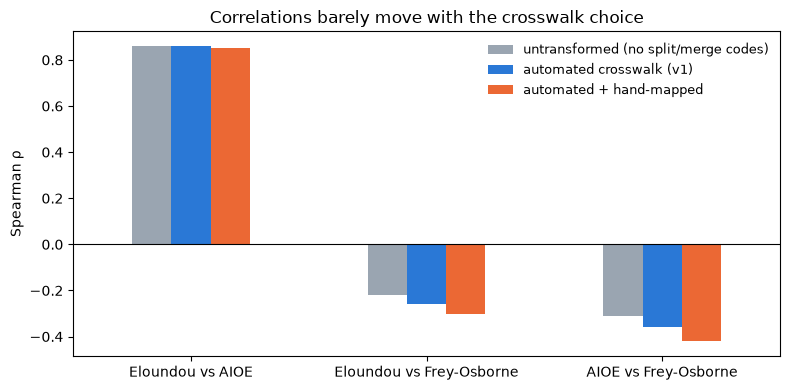

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
sensitivity.drop(columns='n').T.plot.bar(ax=ax, color=['#9aa5b1', '#2a78d6', '#eb6834'], rot=0)
ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel('Spearman ρ')
ax.set_xlabel('')
ax.set_title('Correlations barely move with the crosswalk choice')
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(f'{FIGURES}/ca4_crosswalk_sensitivity.png', dpi=130)
plt.show()

**Takeaway:** the hand-mapped crosswalk brings back large, well-known occupations (physicians, registered nurses,
postsecondary teachers) but moves no correlation by more than 0.06, and the untransformed subset agrees too. If anything the extra rows make the overall disagreement slightly stronger. Caveat: 52 of the 75 added rows copy just two
Frey-Osborne scores (36 postsecondary-teacher codes, 16 physician codes), so they add many ties.
Frey-Osborne shifts the most, as the advisor expected, because 17 of the 18 dropped codes are its codes. The
hand-mapped rows are not added to v1; they live in `data/interim/hand_crosswalk_dropped_codes.csv` (decision log D3).

## 4. "Trade datasets": swap the index variants

Our reading of this note: replace one dataset with an alternative and see whether the findings survive. Eloundou ships
with variants we already have: human raters instead of GPT-4, and α (direct exposure only) or γ (including
LLM-powered tools) instead of β. (Trading data with other teams is out of scope for this notebook.)

In [13]:
variants = {
    'β, GPT-4 (headline)': 'dv_rating_beta', 'β, human raters': 'human_rating_beta',
    'α, GPT-4': 'dv_rating_alpha', 'γ, GPT-4': 'dv_rating_gamma',
}
rows = []
for name, col in variants.items():
    row = {'Eloundou variant': name,
           'vs AIOE': round(stats.spearmanr(v1[col], v1['AIOE'])[0], 2),
           'vs F-O, all': round(stats.spearmanr(v1[col], v1['frey_osborne_probability'])[0], 2)}
    for zone, group in v1.groupby('job_zone'):
        row[f'vs F-O, zone {zone}'] = round(stats.spearmanr(group[col], group['frey_osborne_probability'])[0], 2)
    rows.append(row)
trade = pd.DataFrame(rows).set_index('Eloundou variant')
trade

,vs AIOE,"vs F-O, all","vs F-O, zone 2","vs F-O, zone 3","vs F-O, zone 4","vs F-O, zone 5"
Eloundou variant,,,,,,
"β, GPT-4 (headline)",0.86,-0.26,0.15,0.16,0.24,0.39
"β, human raters",0.86,-0.34,0.08,0.07,0.19,0.25
"α, GPT-4",0.42,0.02,0.11,0.30,0.13,0.10
"γ, GPT-4",0.88,-0.30,0.18,0.12,0.30,0.46


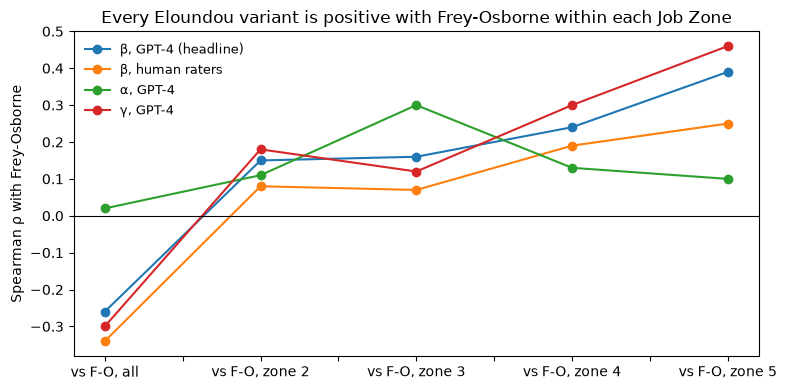

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
trade.filter(like='vs F-O').T.plot(ax=ax, marker='o')
ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel('Spearman ρ with Frey-Osborne')
ax.set_title('Every Eloundou variant is positive with Frey-Osborne within each Job Zone')
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(f'{FIGURES}/ca4_index_variants.png', dpi=130)
plt.show()

**Takeaway:** human raters and γ give the same picture as the headline β, so the finding is not an artifact of GPT-4
doing the rating. α (only tasks an LLM can do directly) is a narrower measure and is not negative overall, but within
every Job Zone all four variants agree positively with Frey-Osborne: the within-Job-Zone result is the robust one.

## 5. Exposure vs risk — sub-issue #26

* **Exposure** (Eloundou, AIOE): how much of a job's tasks AI *could* do or speed up. A highly exposed job may be
  *augmented* (the worker gets faster) rather than replaced.
* **Risk** (Frey-Osborne, 2013, before LLMs): the probability the *whole job* is automated, judged mainly on how
  routine and physical it is.

Plotting exposure against risk splits occupations into four groups. BLS's 2025–35 employment projection is a rough,
independent check of which label matches what forecasters expect.

In [15]:
v1['exposure'] = v1[['pct_eloundou_beta', 'pct_aioe']].mean(axis=1)
high_exp, high_risk = v1['exposure'] >= 50, v1['pct_frey_osborne'] >= 50
v1['quadrant'] = np.select(
    [high_exp & high_risk, high_exp & ~high_risk, ~high_exp & high_risk],
    ['exposed + at risk', 'exposed, low risk (augmented?)', 'at risk, low exposure (physical routine)'],
    'neither')
quad = v1.groupby('quadrant').agg(
    occupations=('soc', 'size'),
    jobs_2025_millions=('bls_emp_2025', lambda s: round(s.sum() / 1000, 1)),
    median_job_zone=('onet_job_zone', 'median'),
    median_wage=('bls_median_wage', 'median'),
    median_growth_pct=('bls_emp_change_pct', 'median'),
)
print('Spearman with BLS projected growth: exposure',
      round(stats.spearmanr(v1['exposure'], v1['bls_emp_change_pct'], nan_policy='omit')[0], 2),
      '| risk', round(stats.spearmanr(v1['pct_frey_osborne'], v1['bls_emp_change_pct'], nan_policy='omit')[0], 2))
within = pd.DataFrame({zone: {
    'exposure vs growth': round(stats.spearmanr(g['exposure'], g['bls_emp_change_pct'], nan_policy='omit')[0], 2),
    'risk vs growth': round(stats.spearmanr(g['pct_frey_osborne'], g['bls_emp_change_pct'], nan_policy='omit')[0], 2),
} for zone, g in v1.groupby('job_zone')})
display(within.add_prefix('zone '))
quad

Spearman with BLS projected growth: exposure 0.14 | risk -0.42


,zone 2,zone 3,zone 4,zone 5
exposure vs growth,-0.02,-0.29,-0.01,-0.30
risk vs growth,-0.22,-0.34,-0.18,-0.15


,occupations,jobs_2025_millions,median_job_zone,median_wage,median_growth_pct
quadrant,,,,,
"at risk, low exposure (physical routine)",238,56.9,2.0,48990.0,1.25
exposed + at risk,110,29.0,3.0,53090.0,-0.05
"exposed, low risk (augmented?)",239,57.5,4.0,80155.0,4.20
neither,106,18.7,3.0,57520.0,3.85


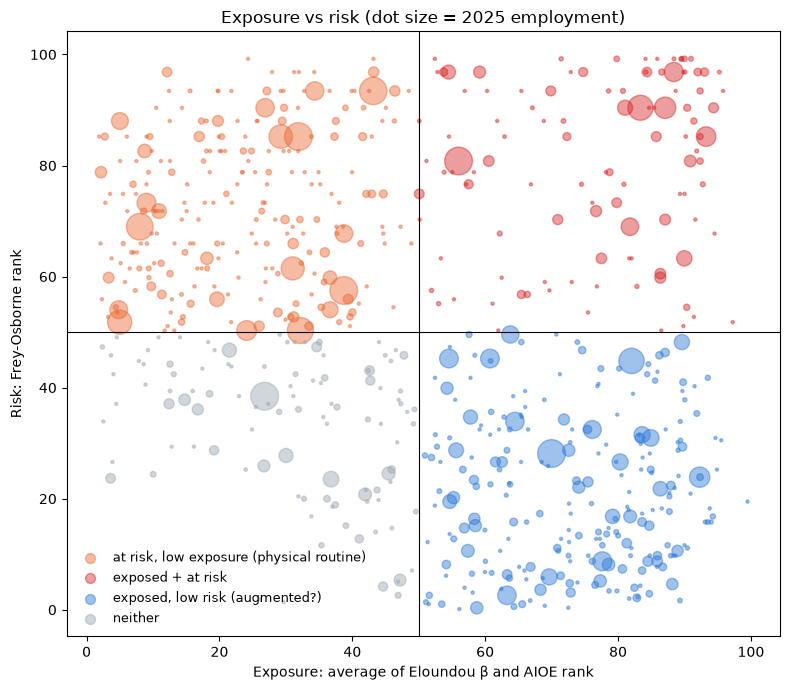

In [16]:
QUAD_COLORS = {'exposed + at risk': '#d62728', 'exposed, low risk (augmented?)': '#2a78d6',
               'at risk, low exposure (physical routine)': '#eb6834', 'neither': '#9aa5b1'}
fig, ax = plt.subplots(figsize=(8, 7))
for name, group in v1.groupby('quadrant'):
    ax.scatter(group['exposure'], group['pct_frey_osborne'], s=np.clip(group['bls_emp_2025'] / 8, 5, 400),
               alpha=0.45, color=QUAD_COLORS[name], label=name)
ax.axhline(50, color='black', lw=0.8)
ax.axvline(50, color='black', lw=0.8)
ax.set_xlabel('Exposure: average of Eloundou β and AIOE rank')
ax.set_ylabel('Risk: Frey-Osborne rank')
ax.set_title('Exposure vs risk (dot size = 2025 employment)')
ax.legend(frameon=False, fontsize=9, loc='lower left', markerscale=0.5)
fig.tight_layout()
fig.savefig(f'{FIGURES}/ca4_exposure_vs_risk.png', dpi=130)
plt.show()

**Takeaway:** "exposed" is not the same as "at risk". The exposed-but-low-risk group is mostly higher-education,
higher-wage work, which BLS still projects to grow (median +4.2%, vs about 0% for exposed + at risk). Frey-Osborne
risk tracks projected decline overall (ρ = −0.42) and within every Job Zone (−0.15 to −0.34). Exposure's small
positive overall link (+0.14) vanishes or turns negative within Job Zone, the same confounder as §1. This is the group Frey-Osborne and the newer indices disagree on,
and it is also what drives the Job Zone confounding in §1.

## 6. Case studies that are relevant to most people — sub-issue #26 (feeds issue #13)

The advisor asked for jobs most people know: **school teachers** and **office workers**. Picked by 2025 employment
(BLS, thousands of jobs), plus registered nurses, who only appear with the hand-mapped crosswalk from §3.

In [17]:
CASES = ['25-2021', '25-2031', '43-9061', '43-6014', '43-4051', '41-2031']
cols = ['title', 'bls_emp_2025', 'bls_emp_change_pct', 'bls_median_wage', 'onet_job_zone',
        'pct_eloundou_beta', 'pct_aioe', 'pct_frey_osborne', 'quadrant']
cases = v1.set_index('soc').loc[CASES, cols].round(1)
nurses = hand_table.loc[['29-1141'], ['title', 'onet_job_zone', 'pct_eloundou_beta', 'pct_aioe', 'pct_frey_osborne']].round(1)
display(cases)
nurses

,title,bls_emp_2025,bls_emp_change_pct,bls_median_wage,onet_job_zone,pct_eloundou_beta,pct_aioe,pct_frey_osborne,quadrant
soc,,,,,,,,,
25-2021,"Elementary School Teachers, Except Special Edu...",1419.3,-0.4,63970.0,4.0,52.4,74.2,2.6,"exposed, low risk (augmented?)"
25-2031,"Secondary School Teachers, Except Special and ...",1087.5,-0.2,72040.0,4.0,54.4,84.8,5.9,"exposed, low risk (augmented?)"
43-9061,"Office Clerks, General",2600.0,-6.0,45010.0,2.0,89.4,77.3,90.4,exposed + at risk
43-6014,"Secretaries and Administrative Assistants, Exc...",1889.8,-6.0,47540.0,2.0,92.9,81.2,90.4,exposed + at risk
43-4051,Customer Service Representatives,2666.0,-5.3,44770.0,2.0,88.3,75.8,44.8,"exposed, low risk (augmented?)"
41-2031,Retail Salespersons,3998.1,-0.3,35410.0,2.0,55.6,56.4,80.8,exposed + at risk


,title,onet_job_zone,pct_eloundou_beta,pct_aioe,pct_frey_osborne
soc,,,,,
29-1141,Registered Nurses,4.4,56.1,55.5,8.1


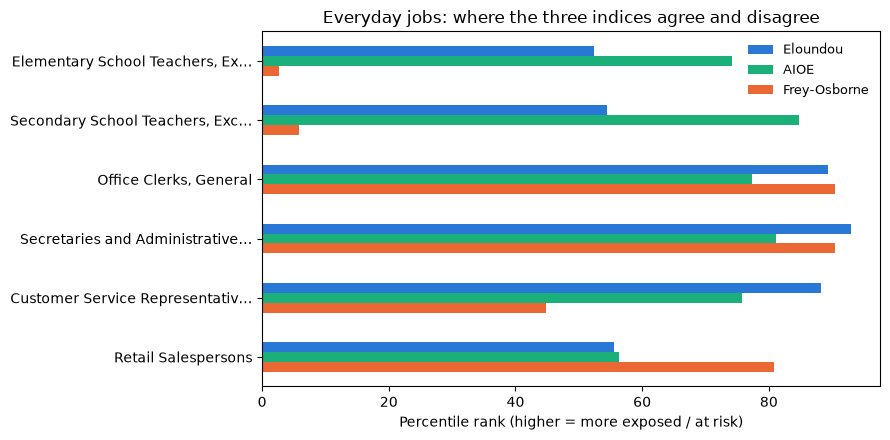

In [18]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_cases = cases[['pct_eloundou_beta', 'pct_aioe', 'pct_frey_osborne']].rename(columns=SHORT)
plot_cases.index = [t if len(t) < 32 else t[:30] + '…' for t in cases['title']]
plot_cases.plot.barh(ax=ax, color=['#2a78d6', '#1baf7a', '#eb6834'])
ax.invert_yaxis()
ax.set_xlabel('Percentile rank (higher = more exposed / at risk)')
ax.set_title('Everyday jobs: where the three indices agree and disagree')
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(f'{FIGURES}/ca4_case_studies.png', dpi=130)
plt.show()

**What the case studies show**

* **School teachers (elementary, secondary):** middle exposure on Eloundou, high on AIOE, but nearly the lowest
  automation risk on Frey-Osborne. AI can help with lesson planning and grading, but the job is social and
  in-person. Classic "exposed, not at risk", and a Job Zone 4 job, which is where §1 finds the disagreement comes from.
* **General office clerks, secretaries and administrative assistants:** high on **all three**. This is where the indices
  agree most, and BLS projects these jobs to shrink (about −6%).
* **Customer service representatives:** highly exposed (chat and email support) but only middle risk on
  Frey-Osborne, which in 2013 could not foresee language models handling conversation.
* **Retail salespersons:** middle exposure, high Frey-Osborne risk: the in-person, routine side of the job is what
  Frey-Osborne scores.
* **Registered nurses** (hand-mapped, §3): middle exposure on both newer indices, very low Frey-Osborne risk: the
  same "exposed, not at risk" pattern as teachers. (Nurse percentiles rank among the 768 hand-mapped occupations,
  not 693, so compare them loosely.)

Full write-ups of six case studies remain open in issue #13; these numbers are the starting point.